# Data Visualization & Analysis Before Training
Comprehensive visualization of the vehicle detection dataset to understand data quality and distribution.

## Section 0: Imports and Setup

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
import random
from collections import defaultdict
import seaborn as sns

# Configuration
OUTPUT_DIR = "vehicle_dataset"
SPLITS = ["train", "val", "test"]
random.seed(42)
np.random.seed(42)

# Matplotlib settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("Setup complete")

Setup complete


## Section 1: Dataset Statistics
Analyze image dimensions, box sizes, and count statistics across all splits.

In [2]:
def collect_dataset_stats():
    """Collect statistics about images and bounding boxes."""
    stats = {
        "image_heights": [],
        "image_widths": [],
        "box_widths": [],
        "box_heights": [],
        "boxes_per_image": [],
        "split_counts": {split: 0 for split in SPLITS}
    }
    
    for split in SPLITS:
        img_dir = os.path.join(OUTPUT_DIR, "images", split)
        label_dir = os.path.join(OUTPUT_DIR, "labels", split)
        
        images = list(Path(img_dir).glob("*.jpg"))
        stats["split_counts"][split] = len(images)
        
        for img_path in images:
            # Image dimensions
            img = cv2.imread(str(img_path))
            if img is not None:
                h, w, _ = img.shape
                stats["image_heights"].append(h)
                stats["image_widths"].append(w)
            
            # Bounding box statistics
            label_path = str(img_path).replace("images", "labels").replace(".jpg", ".txt")
            if os.path.exists(label_path):
                with open(label_path, "r") as f:
                    lines = f.readlines()
                    stats["boxes_per_image"].append(len(lines))
                    
                    for line in lines:
                        parts = line.strip().split()
                        if len(parts) >= 5:
                            # YOLO format: class_id x_center y_center width height (normalized)
                            box_w = float(parts[3])
                            box_h = float(parts[4])
                            stats["box_widths"].append(box_w)
                            stats["box_heights"].append(box_h)
    
    return stats

stats = collect_dataset_stats()

# Print statistics
print("="*60)
print("DATASET STATISTICS")
print("="*60)

print("\n[Dataset Split]")
total = sum(stats["split_counts"].values())
for split, count in stats["split_counts"].items():
    percentage = (count / total) * 100
    print(f"  {split.upper():6s}: {count:4d} images ({percentage:5.1f}%)")
print(f"  {'TOTAL':6s}: {total:4d} images")

print("\n[Image Dimensions]")
print(f"  Width  - Mean: {np.mean(stats['image_widths']):.1f}, Std: {np.std(stats['image_widths']):.1f}")
print(f"  Height - Mean: {np.mean(stats['image_heights']):.1f}, Std: {np.std(stats['image_heights']):.1f}")
print(f"  All images: {int(np.mean(stats['image_widths']))} x {int(np.mean(stats['image_heights']))} px")

print("\n[Bounding Box Statistics (Normalized 0-1)]")
print(f"  Width  - Mean: {np.mean(stats['box_widths']):.4f}, Std: {np.std(stats['box_widths']):.4f}")
print(f"  Width  - Min: {np.min(stats['box_widths']):.4f}, Max: {np.max(stats['box_widths']):.4f}")
print(f"  Height - Mean: {np.mean(stats['box_heights']):.4f}, Std: {np.std(stats['box_heights']):.4f}")
print(f"  Height - Min: {np.min(stats['box_heights']):.4f}, Max: {np.max(stats['box_heights']):.4f}")

print("\n[Vehicles per Image]")
print(f"  Mean: {np.mean(stats['boxes_per_image']):.2f}, Std: {np.std(stats['boxes_per_image']):.2f}")
print(f"  Min: {np.min(stats['boxes_per_image'])}, Max: {np.max(stats['boxes_per_image'])}")
print(f"  Total vehicles: {len(stats['box_widths'])}")

DATASET STATISTICS

[Dataset Split]
  TRAIN : 1050 images ( 70.0%)
  VAL   :  300 images ( 20.0%)
  TEST  :  150 images ( 10.0%)
  TOTAL : 1500 images

[Image Dimensions]
  Width  - Mean: 960.0, Std: 0.0
  Height - Mean: 540.0, Std: 0.0
  All images: 960 x 540 px

[Bounding Box Statistics (Normalized 0-1)]
  Width  - Mean: 0.1035, Std: 0.0743
  Width  - Min: 0.0117, Max: 0.9248
  Height - Mean: 0.1184, Std: 0.0827
  Height - Min: 0.0083, Max: 0.8209

[Vehicles per Image]
  Mean: 9.07, Std: 6.43
  Min: 1, Max: 40
  Total vehicles: 13607


## Section 2: Data Split Visualization
Pie chart showing train/val/test distribution.

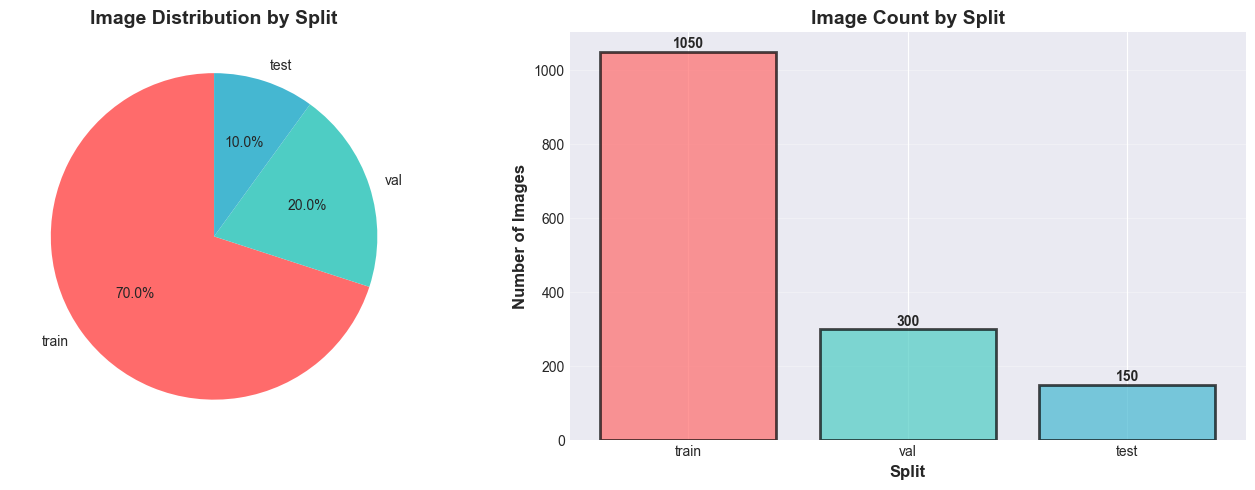

Visualization saved: results/data_split_visualization.png


In [3]:
# Data Split Pie Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart for image count
splits = list(stats["split_counts"].keys())
counts = list(stats["split_counts"].values())
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

axes[0].pie(counts, labels=splits, autopct='%1.1f%%', colors=colors, startangle=90)
axes[0].set_title('Image Distribution by Split', fontsize=14, fontweight='bold')

# Bar chart for image count
axes[1].bar(splits, counts, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
axes[1].set_ylabel('Number of Images', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Split', fontsize=12, fontweight='bold')
axes[1].set_title('Image Count by Split', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

# Add count labels on bars
for i, (split, count) in enumerate(zip(splits, counts)):
    axes[1].text(i, count + 10, str(count), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('results/data_split_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("Visualization saved: results/data_split_visualization.png")

## Section 3: Box Size Distribution
Histograms of bounding box dimensions.

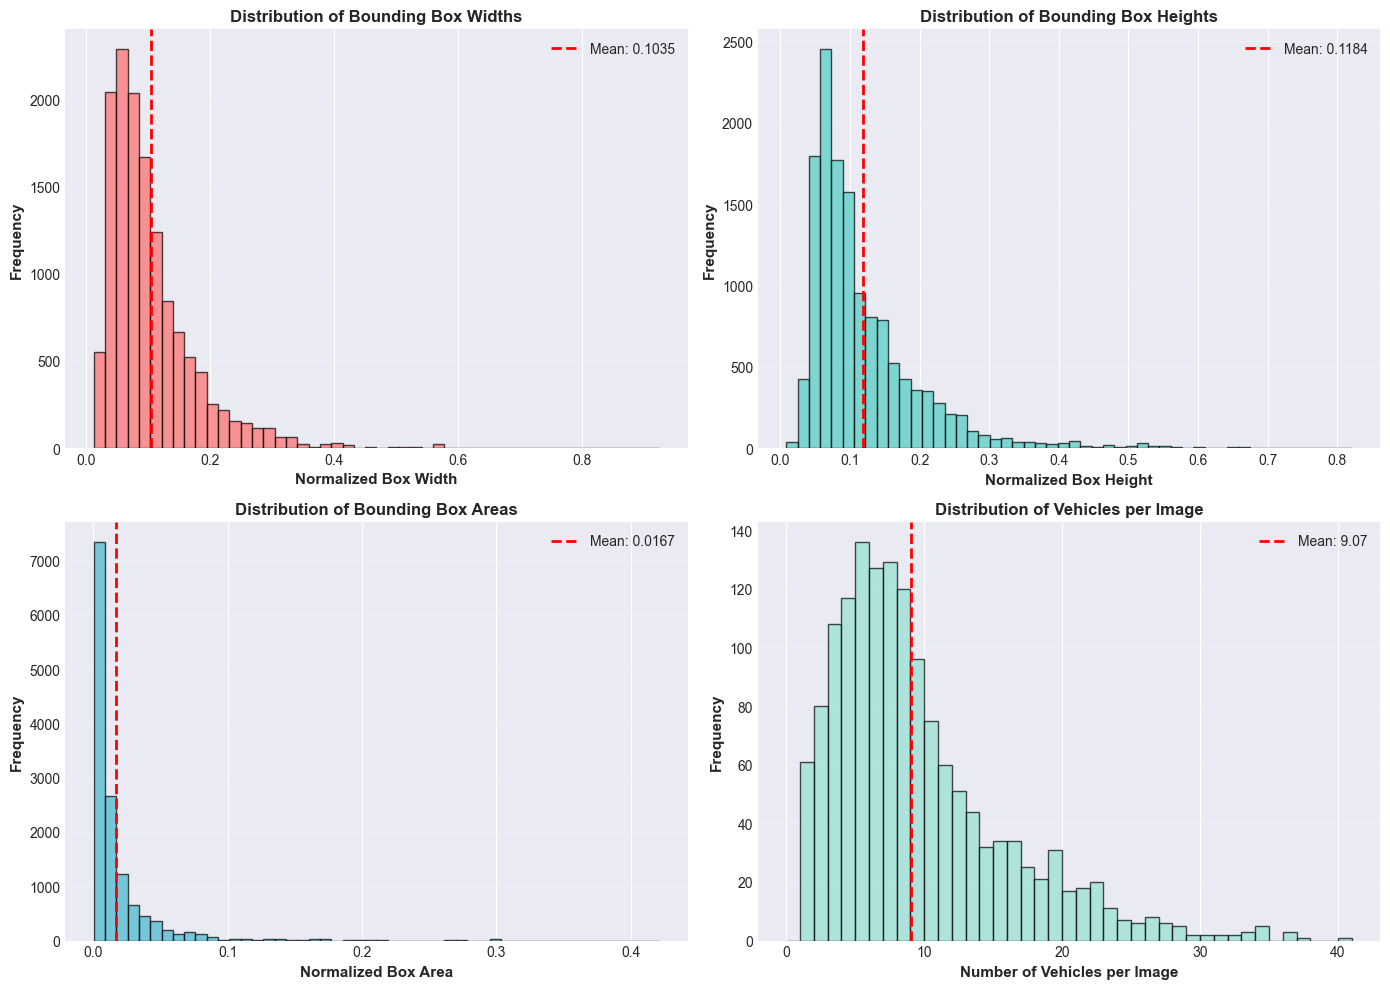

Visualization saved: results/box_size_distribution.png


In [4]:
# Bounding Box Size Distribution
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Box Width Distribution
axes[0, 0].hist(stats['box_widths'], bins=50, color='#FF6B6B', alpha=0.7, edgecolor='black')
axes[0, 0].set_xlabel('Normalized Box Width', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[0, 0].set_title('Distribution of Bounding Box Widths', fontsize=12, fontweight='bold')
axes[0, 0].grid(axis='y', alpha=0.3)
axes[0, 0].axvline(np.mean(stats['box_widths']), color='red', linestyle='--', linewidth=2, label=f"Mean: {np.mean(stats['box_widths']):.4f}")
axes[0, 0].legend()

# Box Height Distribution
axes[0, 1].hist(stats['box_heights'], bins=50, color='#4ECDC4', alpha=0.7, edgecolor='black')
axes[0, 1].set_xlabel('Normalized Box Height', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Distribution of Bounding Box Heights', fontsize=12, fontweight='bold')
axes[0, 1].grid(axis='y', alpha=0.3)
axes[0, 1].axvline(np.mean(stats['box_heights']), color='red', linestyle='--', linewidth=2, label=f"Mean: {np.mean(stats['box_heights']):.4f}")
axes[0, 1].legend()

# Box Area Distribution
box_areas = [w * h for w, h in zip(stats['box_widths'], stats['box_heights'])]
axes[1, 0].hist(box_areas, bins=50, color='#45B7D1', alpha=0.7, edgecolor='black')
axes[1, 0].set_xlabel('Normalized Box Area', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[1, 0].set_title('Distribution of Bounding Box Areas', fontsize=12, fontweight='bold')
axes[1, 0].grid(axis='y', alpha=0.3)
axes[1, 0].axvline(np.mean(box_areas), color='red', linestyle='--', linewidth=2, label=f"Mean: {np.mean(box_areas):.4f}")
axes[1, 0].legend()

# Boxes per Image Distribution
axes[1, 1].hist(stats['boxes_per_image'], bins=range(0, max(stats['boxes_per_image'])+2), color='#95E1D3', alpha=0.7, edgecolor='black')
axes[1, 1].set_xlabel('Number of Vehicles per Image', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Frequency', fontsize=11, fontweight='bold')
axes[1, 1].set_title('Distribution of Vehicles per Image', fontsize=12, fontweight='bold')
axes[1, 1].grid(axis='y', alpha=0.3)
axes[1, 1].axvline(np.mean(stats['boxes_per_image']), color='red', linestyle='--', linewidth=2, label=f"Mean: {np.mean(stats['boxes_per_image']):.2f}")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('results/box_size_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("Visualization saved: results/box_size_distribution.png")

## Section 4: Sample Grid Visualization
Display multiple images with bounding boxes in a grid layout.

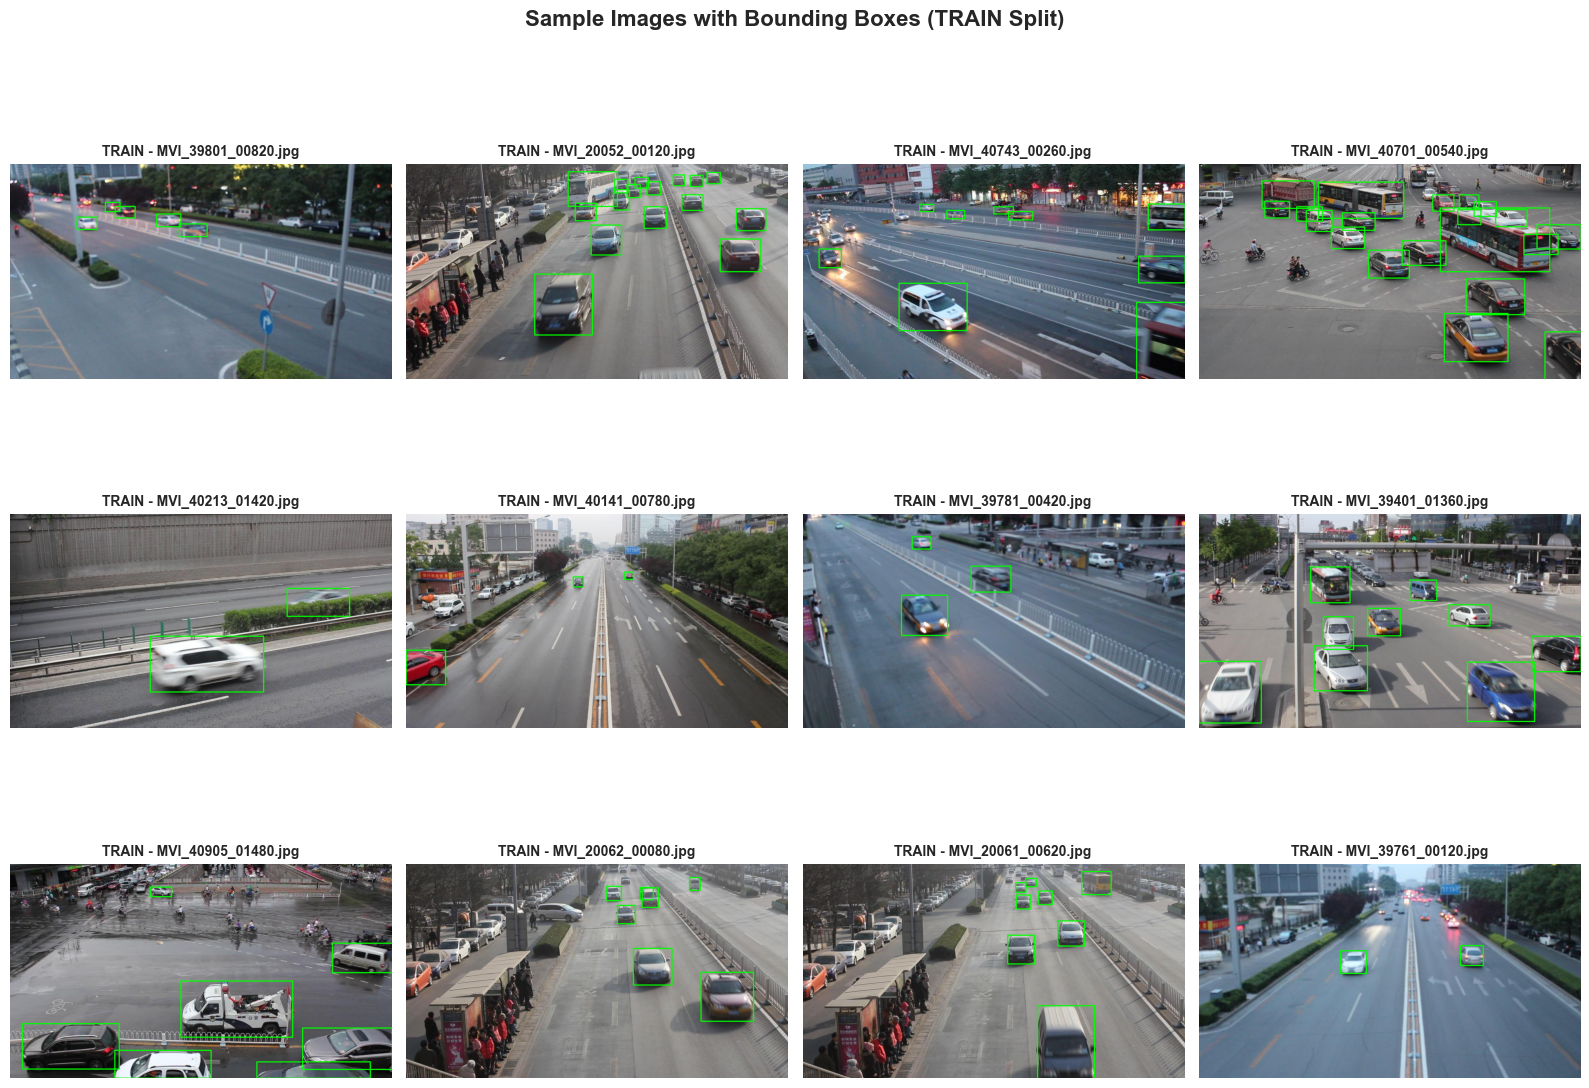

Sample grid saved for train split


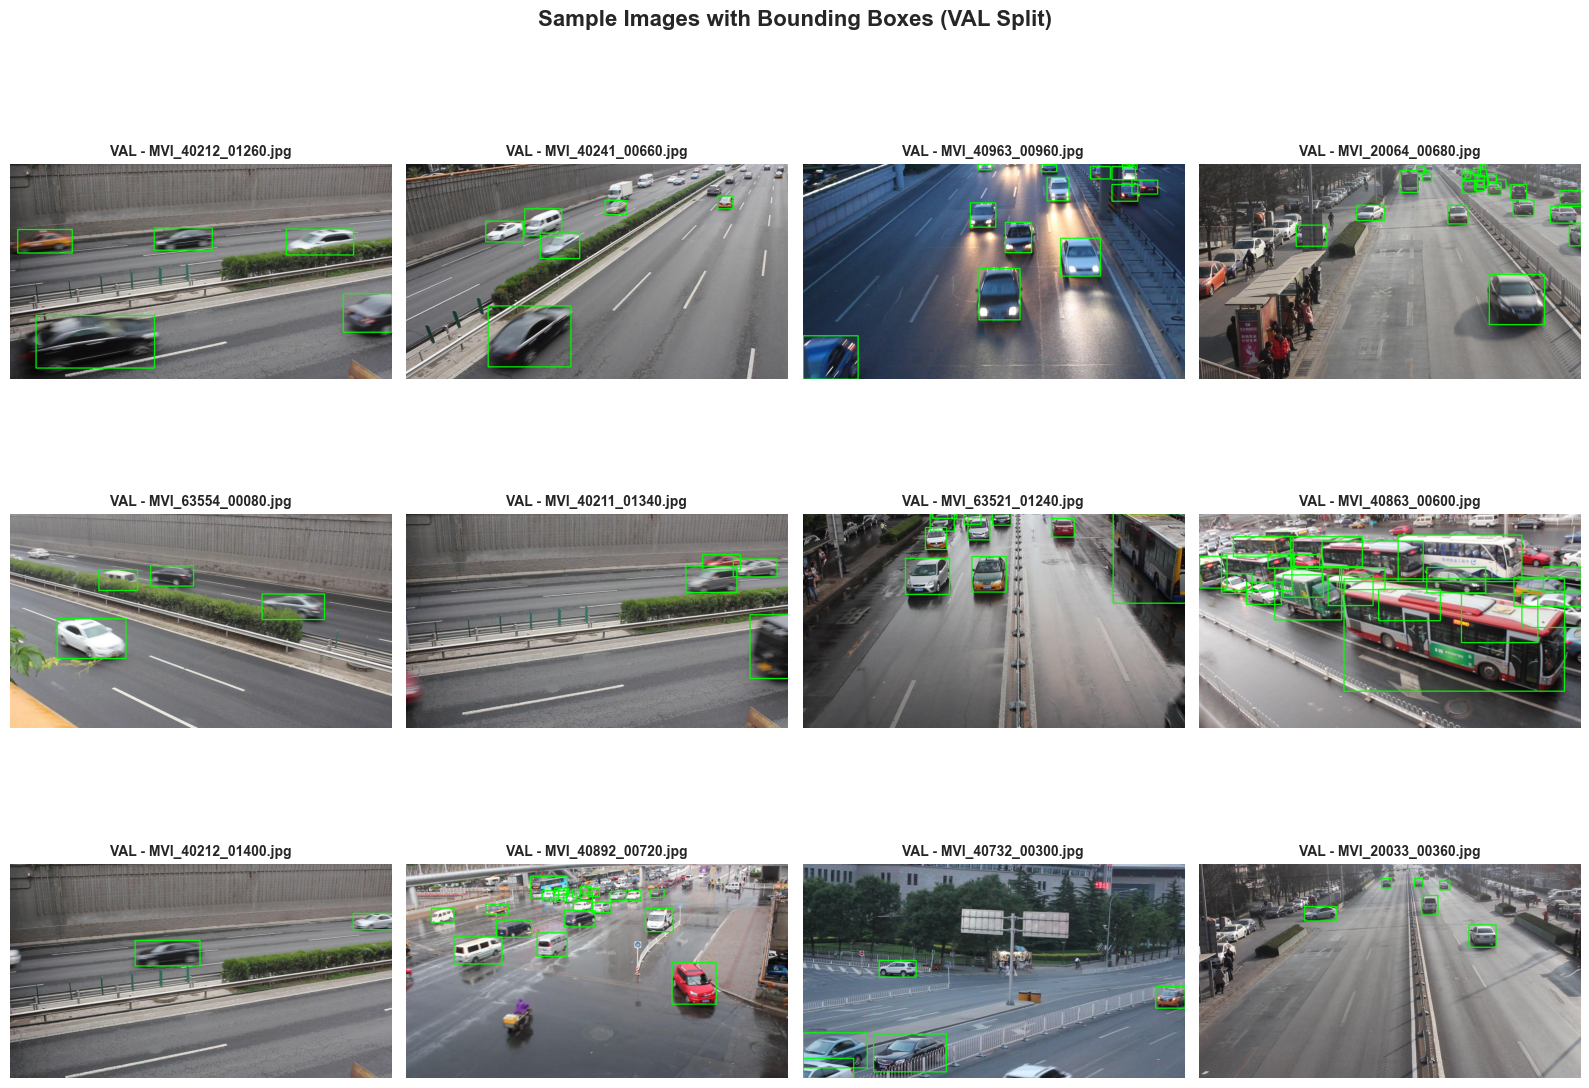

Sample grid saved for val split


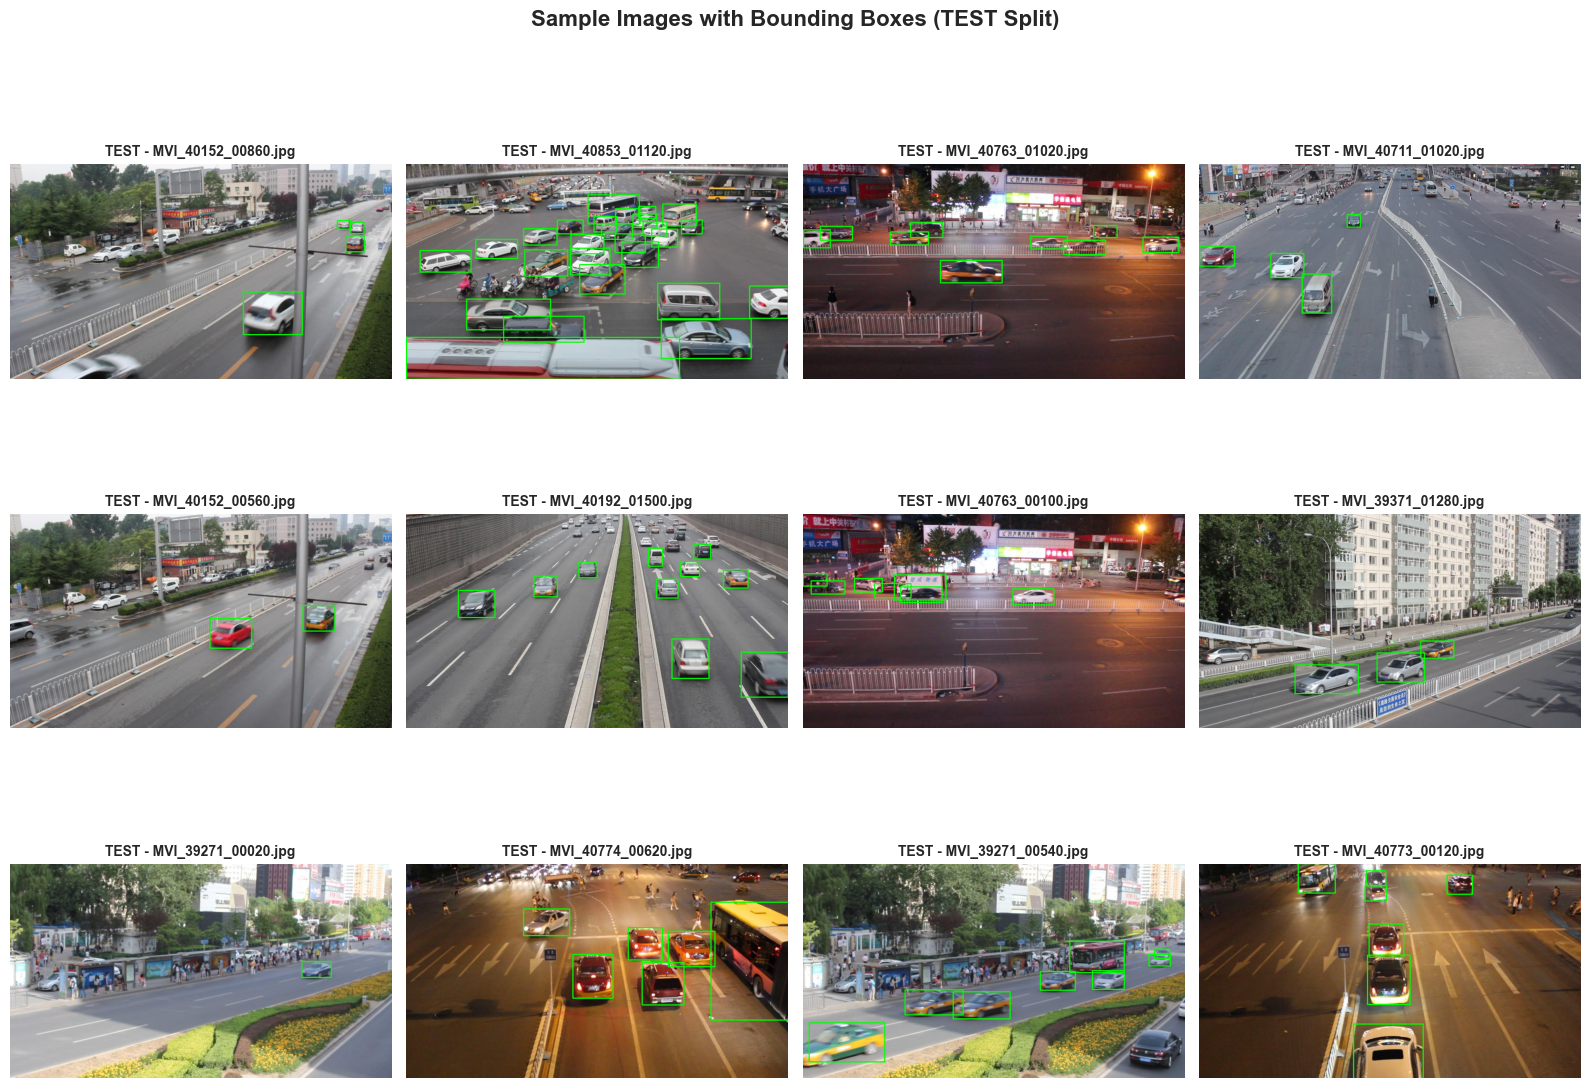

Sample grid saved for test split


In [5]:
def visualize_sample_grid(split='train', n_samples=12, grid_size=(3, 4)):
    """Display a grid of sample images with bounding boxes."""
    img_dir = os.path.join(OUTPUT_DIR, "images", split)
    label_dir = os.path.join(OUTPUT_DIR, "labels", split)
    
    images = list(Path(img_dir).glob("*.jpg"))
    sample_images = random.sample(images, min(n_samples, len(images)))
    
    fig, axes = plt.subplots(grid_size[0], grid_size[1], figsize=(16, 12))
    axes = axes.flatten()
    
    for idx, img_path in enumerate(sample_images):
        img = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape
        
        # Read and draw bounding boxes
        label_path = str(img_path).replace("images", "labels").replace(".jpg", ".txt")
        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        _, x, y, bw, bh = map(float, parts)
                        x1 = int((x - bw / 2) * w)
                        y1 = int((y - bh / 2) * h)
                        x2 = int((x + bw / 2) * w)
                        y2 = int((y + bh / 2) * h)
                        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)
        
        axes[idx].imshow(img_rgb)
        axes[idx].set_title(f"{split.upper()} - {img_path.name}", fontsize=10, fontweight='bold')
        axes[idx].axis('off')
    
    # Hide unused subplots
    for idx in range(len(sample_images), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(f'Sample Images with Bounding Boxes ({split.upper()} Split)', fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig(f'results/sample_grid_{split}.png', dpi=150, bbox_inches='tight')
    plt.show()

# Visualize each split
for split in SPLITS:
    visualize_sample_grid(split=split, n_samples=12)
    print(f"Sample grid saved for {split} split")

## Section 5: Image Augmentation Preview
Show examples of common augmentation techniques applied to dataset images.

IndexError: index 10 is out of bounds for axis 0 with size 10

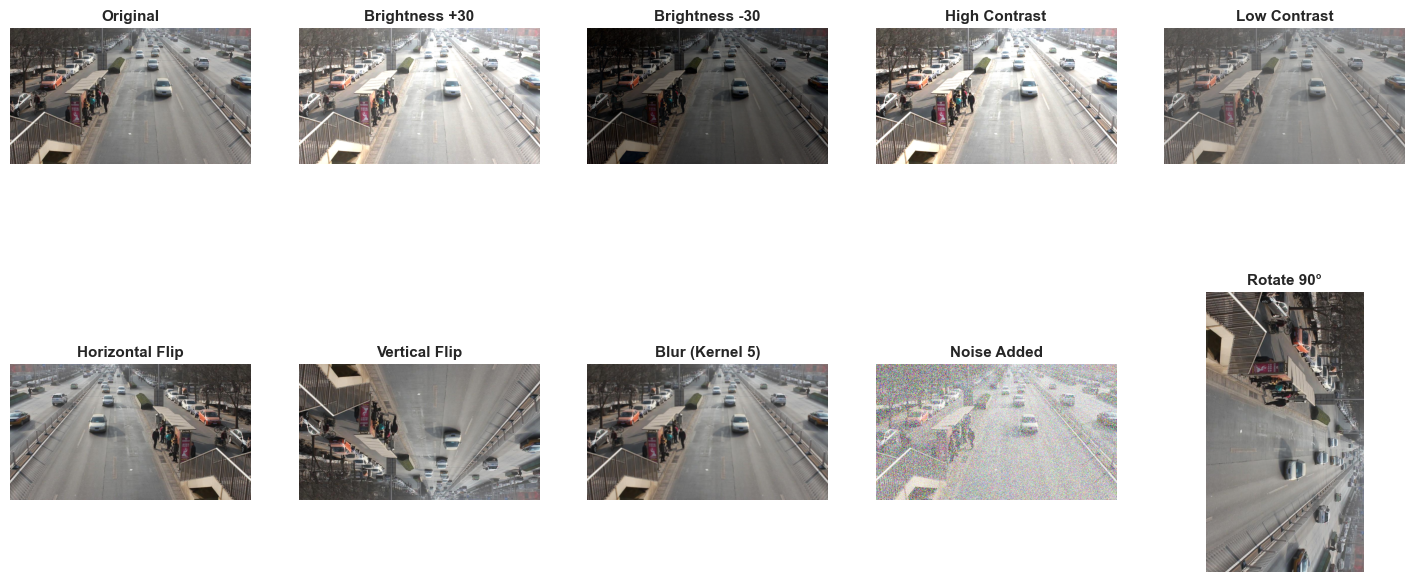

In [6]:
# Simple augmentation preview without external libraries
def augment_image_preview(img):
    """Apply various augmentations to preview."""
    h, w, c = img.shape
    
    augmented = {}
    
    # Original
    augmented['Original'] = img.copy()
    
    # Brightness adjustment
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    brightness = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    augmented['Brightness +30'] = cv2.convertScaleAbs(img, alpha=1.3, beta=30)
    augmented['Brightness -30'] = cv2.convertScaleAbs(img, alpha=0.7, beta=-30)
    
    # Contrast adjustment
    augmented['High Contrast'] = cv2.convertScaleAbs(img, alpha=1.5, beta=0)
    augmented['Low Contrast'] = cv2.convertScaleAbs(img, alpha=0.7, beta=50)
    
    # Horizontal flip
    augmented['Horizontal Flip'] = cv2.flip(img, 1)
    
    # Vertical flip (less common for traffic)
    augmented['Vertical Flip'] = cv2.flip(img, 0)
    
    # Gaussian blur
    augmented['Blur (Kernel 5)'] = cv2.GaussianBlur(img, (5, 5), 0)
    
    # Add noise
    noise = np.random.normal(0, 10, img.shape).astype(np.uint8)
    augmented['Noise Added'] = cv2.add(img, noise)
    
    # Rotation (90, 180, 270)
    augmented['Rotate 90°'] = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
    augmented['Rotate 180°'] = cv2.rotate(img, cv2.ROTATE_180)
    
    return augmented

# Get a sample image
sample_img_path = list(Path(os.path.join(OUTPUT_DIR, "images", "train")).glob("*.jpg"))[0]
sample_img = cv2.imread(str(sample_img_path))
sample_img = cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB)

augmented_imgs = augment_image_preview(sample_img)

# Visualize augmentations
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for idx, (aug_name, aug_img) in enumerate(augmented_imgs.items()):
    # Ensure image is in valid range
    aug_img_display = np.clip(aug_img, 0, 255).astype(np.uint8)
    axes[idx].imshow(aug_img_display)
    axes[idx].set_title(aug_name, fontsize=11, fontweight='bold')
    axes[idx].axis('off')

# Hide unused subplots
for idx in range(len(augmented_imgs), len(axes)):
    axes[idx].axis('off')

plt.suptitle('Image Augmentation Techniques for Training', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('results/augmentation_preview.png', dpi=150, bbox_inches='tight')
plt.show()

print("Augmentation preview saved: results/augmentation_preview.png")

## Section 6: Before & After Preprocessing Comparison
Show original vs preprocessed images side by side.

In [ ]:
# Create a summary statistics figure
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3, hspace=0.4, wspace=0.3)

# Title
fig.suptitle('Data Preprocessing Summary', fontsize=18, fontweight='bold', y=0.98)

# 1. Dataset Split (top left)
ax1 = fig.add_subplot(gs[0, 0])
splits_list = list(stats["split_counts"].keys())
counts_list = list(stats["split_counts"].values())
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
ax1.pie(counts_list, labels=splits_list, autopct='%1.1f%%', colors=colors)
ax1.set_title('Data Split Distribution', fontweight='bold')

# 2. Image dimensions (top middle)
ax2 = fig.add_subplot(gs[0, 1])
ax2.text(0.5, 0.7, 'Image Dimensions', ha='center', fontsize=12, fontweight='bold', transform=ax2.transAxes)
ax2.text(0.5, 0.5, f"{int(np.mean(stats['image_widths']))} × {int(np.mean(stats['image_heights']))} px", 
         ha='center', fontsize=14, fontweight='bold', transform=ax2.transAxes, color='#FF6B6B')
ax2.text(0.5, 0.3, f"Total Images: {sum(stats['split_counts'].values())}", 
         ha='center', fontsize=11, transform=ax2.transAxes)
ax2.text(0.5, 0.1, f"Total Vehicles: {len(stats['box_widths'])}", 
         ha='center', fontsize=11, transform=ax2.transAxes)
ax2.axis('off')
ax2.set_title('Dataset Size', fontweight='bold')

# 3. Box statistics (top right)
ax3 = fig.add_subplot(gs[0, 2])
ax3.text(0.5, 0.8, 'Box Statistics (Normalized)', ha='center', fontsize=11, fontweight='bold', transform=ax3.transAxes)
ax3.text(0.5, 0.6, f"Width: {np.mean(stats['box_widths']):.4f} ± {np.std(stats['box_widths']):.4f}", 
         ha='center', fontsize=10, transform=ax3.transAxes)
ax3.text(0.5, 0.45, f"Height: {np.mean(stats['box_heights']):.4f} ± {np.std(stats['box_heights']):.4f}", 
         ha='center', fontsize=10, transform=ax3.transAxes)
ax3.text(0.5, 0.3, f"Avg Vehicles/Image: {np.mean(stats['boxes_per_image']):.2f}", 
         ha='center', fontsize=10, transform=ax3.transAxes)
ax3.text(0.5, 0.15, f"Max Vehicles/Image: {max(stats['boxes_per_image'])}", 
         ha='center', fontsize=10, transform=ax3.transAxes)
ax3.axis('off')
ax3.set_title('Annotations Stats', fontweight='bold')

# 4. Box width distribution (middle left)
ax4 = fig.add_subplot(gs[1, 0])
ax4.hist(stats['box_widths'], bins=40, color='#FF6B6B', alpha=0.7, edgecolor='black')
ax4.set_xlabel('Normalized Width')
ax4.set_ylabel('Frequency')
ax4.set_title('Box Width Distribution', fontweight='bold')
ax4.grid(axis='y', alpha=0.3)

# 5. Box height distribution (middle middle)
ax5 = fig.add_subplot(gs[1, 1])
ax5.hist(stats['box_heights'], bins=40, color='#4ECDC4', alpha=0.7, edgecolor='black')
ax5.set_xlabel('Normalized Height')
ax5.set_ylabel('Frequency')
ax5.set_title('Box Height Distribution', fontweight='bold')
ax5.grid(axis='y', alpha=0.3)

# 6. Vehicles per image (middle right)
ax6 = fig.add_subplot(gs[1, 2])
ax6.hist(stats['boxes_per_image'], bins=range(0, max(stats['boxes_per_image'])+2), 
         color='#45B7D1', alpha=0.7, edgecolor='black')
ax6.set_xlabel('Count')
ax6.set_ylabel('Frequency')
ax6.set_title('Vehicles per Image', fontweight='bold')
ax6.grid(axis='y', alpha=0.3)

# 7. Image count bar chart (bottom, spanning 3 columns)
ax7 = fig.add_subplot(gs[2, :])
splits_list = list(stats["split_counts"].keys())
counts_list = list(stats["split_counts"].values())
bars = ax7.bar(splits_list, counts_list, color=colors, alpha=0.7, edgecolor='black', linewidth=2, width=0.6)
ax7.set_ylabel('Number of Images', fontweight='bold')
ax7.set_xlabel('Dataset Split', fontweight='bold')
ax7.set_title('Image Count by Split', fontweight='bold')
ax7.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax7.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}',
            ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.savefig('results/preprocessing_summary.png', dpi=150, bbox_inches='tight')
plt.show()

print("Preprocessing summary saved: results/preprocessing_summary.png")

## Summary

All visualizations have been generated and saved to the `results/` directory:

1. **data_split_visualization.png** - Train/Val/Test distribution
2. **box_size_distribution.png** - Bounding box statistics
3. **sample_grid_train/val/test.png** - Sample images with boxes
4. **augmentation_preview.png** - Data augmentation examples
5. **preprocessing_summary.png** - Complete summary dashboard

These visualizations are ready to include in your presentation slides!